# CLASIFICACIÓN DE SUPERVIVENCIA DEL TITANIC CON ÁRBOL DE DECISIÓN + ROC

**Instructor:** Fran - Universidad Nacional del Oeste (UNO)  
**Fecha:** 22 de Noviembre de 2025  
**Dataset:** Titanic Survival (Kaggle / UCI ML Repository)

## Objetivo Pedagógico:

1. Predecir supervivencia de pasajeros del Titanic usando árbol de decisión
2. Evaluar el modelo con métricas de clasificación (precision, recall, F1)
3. Construir y analizar curva ROC + AUC
4. Discutir sesgos y equidad en modelos predictivos

## Variables:

- **Pclass:** Clase del pasajero (1 = Primera, 2 = Segunda, 3 = Tercera)
- **Sex:** Sexo (male/female)
- **Age:** Edad en años
- **SibSp:** Número de hermanos/cónyuges a bordo
- **Parch:** Número de padres/hijos a bordo
- **Fare:** Tarifa pagada por el ticket
- **Embarked:** Puerto de embarque (C=Cherbourg, Q=Queenstown, S=Southampton)
- **Survived:** 0 = Murió, 1 = Sobrevivió (**VARIABLE OBJETIVO**)

## PASO 1: CARGAR LIBRERÍAS NECESARIAS

In [2]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    accuracy_score,
    precision_score, 
    recall_score, 
    f1_score,
    roc_curve, 
    roc_auc_score,
    RocCurveDisplay
)

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# Configuración de pandas para mostrar más filas/columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("✓ Librerías cargadas exitosamente")

✓ Librerías cargadas exitosamente


## PASO 2: DESCARGAR Y CARGAR EL DATASET TITANIC

In [3]:
print("=== DESCARGANDO DATASET TITANIC SURVIVAL ===")

# URL del dataset Titanic (versión completa con train + test etiquetado)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

# Descargar dataset
titanic_raw = pd.read_csv(url)

print("✓ Dataset descargado")
print(f"\nDimensiones: {titanic_raw.shape[0]} filas × {titanic_raw.shape[1]} columnas")

=== DESCARGANDO DATASET TITANIC SURVIVAL ===
✓ Dataset descargado

Dimensiones: 891 filas × 12 columnas


## PASO 3: EXPLORACIÓN INICIAL DE DATOS

In [4]:
print("=== EXPLORACIÓN INICIAL DEL DATASET ===")
print("\nInformación general:")
titanic_raw.info()

=== EXPLORACIÓN INICIAL DEL DATASET ===

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
print("\nPrimeras 6 observaciones:")
titanic_raw.head(6)


Primeras 6 observaciones:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


In [7]:
print("\nResumen estadístico de las variables:")
titanic_raw.describe()


Resumen estadístico de las variables:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
# Balance de clases (¿cuántos sobrevivieron vs. murieron?)
print("\nBalance de clases (sin procesamiento):")
balance_clases = titanic_raw['Survived'].value_counts().sort_index()
balance_clases.index = ['Died', 'Survived']
print(balance_clases)

# Calcular proporciones
prop_clases = titanic_raw['Survived'].value_counts(normalize=True).sort_index() * 100
prop_clases.index = ['Died', 'Survived']

print("\nProporciones:")
print(f"  Died:     {prop_clases['Died']:.1f}% ({balance_clases['Died']} pasajeros)")
print(f"  Survived: {prop_clases['Survived']:.1f}% ({balance_clases['Survived']} pasajeros)")


Balance de clases (sin procesamiento):
Died        549
Survived    342
Name: count, dtype: int64

Proporciones:
  Died:     61.6% (549 pasajeros)
  Survived: 38.4% (342 pasajeros)


In [9]:
# Análisis de valores faltantes
print("\nAnálisis de valores faltantes:")
missing_count = titanic_raw.isnull().sum()
missing_pct = (missing_count / len(titanic_raw)) * 100

missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Pct': missing_pct
})

missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(
    'Missing_Count', ascending=False
)

if len(missing_summary) > 0:
    print(missing_summary)
    print("\n⚠ IMPORTANTE: Hay valores faltantes que debemos manejar")
else:
    print("✓ No hay valores faltantes")


Análisis de valores faltantes:
          Missing_Count  Missing_Pct
Cabin               687    77.104377
Age                 177    19.865320
Embarked              2     0.224467

⚠ IMPORTANTE: Hay valores faltantes que debemos manejar


## PASO 4: PREPARACIÓN Y LIMPIEZA DE DATOS

In [5]:
print("=== PREPARACIÓN DE DATOS ===")

# Seleccionar solo las variables que vamos a usar
# Descartamos: PassengerId (ID), Name (texto), Ticket (texto), Cabin (muchos NAs)
titanic = titanic_raw[[
    'Survived',    # Variable objetivo
    'Pclass',      # Clase socioeconómica
    'Sex',         # Sexo
    'Age',         # Edad
    'SibSp',       # Hermanos/cónyuges
    'Parch',       # Padres/hijos
    'Fare',        # Tarifa pagada
    'Embarked'     # Puerto de embarque
]].copy()

print("\nVariables seleccionadas para el modelo:")
print(", ".join(titanic.columns))

=== PREPARACIÓN DE DATOS ===

Variables seleccionadas para el modelo:
Survived, Pclass, Sex, Age, SibSp, Parch, Fare, Embarked


In [6]:
# Manejar valores faltantes
print("\nMANEJO DE VALORES FALTANTES:\n")

# Age: Imputar con la mediana (más robusta que la media)
age_median = titanic['Age'].median()
n_age_missing = titanic['Age'].isnull().sum()
pct_age_missing = (n_age_missing / len(titanic)) * 100

print(f"• Age: {n_age_missing} valores faltantes ({pct_age_missing:.1f}%)")
print(f"  → Imputando con la mediana: {age_median:.1f} años")
titanic['Age'].fillna(age_median, inplace=True)

# Embarked: Imputar con la moda (valor más frecuente)
n_embarked_missing = titanic['Embarked'].isnull().sum()
if n_embarked_missing > 0:
    embarked_mode = titanic['Embarked'].mode()[0]
    print(f"\n• Embarked: {n_embarked_missing} valores faltantes")
    print(f"  → Imputando con la moda: {embarked_mode}")
    titanic['Embarked'].fillna(embarked_mode, inplace=True)

# Fare: Verificar si hay NAs (raro, pero por las dudas)
n_fare_missing = titanic['Fare'].isnull().sum()
if n_fare_missing > 0:
    fare_median = titanic['Fare'].median()
    print(f"\n• Fare: {n_fare_missing} valores faltantes")
    print(f"  → Imputando con la mediana: {fare_median:.2f}")
    titanic['Fare'].fillna(fare_median, inplace=True)

# Verificar que no queden NAs
print("\n✓ Valores faltantes después de imputación:")
print(titanic.isnull().sum())


MANEJO DE VALORES FALTANTES:

• Age: 177 valores faltantes (19.9%)
  → Imputando con la mediana: 28.0 años

• Embarked: 2 valores faltantes
  → Imputando con la moda: S

✓ Valores faltantes después de imputación:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


C:\Users\frana\AppData\Local\Temp\ipykernel_28696\2367236280.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic['Age'].fillna(age_median, inplace=True)
C:\Users\frana\AppData\Local\Temp\ipykernel_28696\2367236280.py:19: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For ex

## PASO 5: ANÁLISIS EXPLORATORIO RÁPIDO (SESGOS EVIDENTES)

In [7]:
print("=== ANÁLISIS EXPLORATORIO: SESGOS EVIDENTES ===")
print("\n1. SUPERVIVENCIA POR SEXO:")

# Crear tabla de contingencia
tabla_sex = pd.crosstab(titanic['Sex'], titanic['Survived'], normalize='index') * 100
tabla_sex.columns = ['Died', 'Survived']

print(tabla_sex.round(1))

print("\nInterpretación:")
print(f"  • {tabla_sex.loc['female', 'Survived']:.1f}% de las MUJERES sobrevivieron")
print(f"  • {tabla_sex.loc['male', 'Survived']:.1f}% de los HOMBRES sobrevivieron")
print("  → SESGO EVIDENTE: Política 'Mujeres y niños primero'")

=== ANÁLISIS EXPLORATORIO: SESGOS EVIDENTES ===

1. SUPERVIVENCIA POR SEXO:
        Died  Survived
Sex                   
female  25.8      74.2
male    81.1      18.9

Interpretación:
  • 74.2% de las MUJERES sobrevivieron
  • 18.9% de los HOMBRES sobrevivieron
  → SESGO EVIDENTE: Política 'Mujeres y niños primero'


In [8]:
print("\n2. SUPERVIVENCIA POR CLASE SOCIOECONÓMICA:")

tabla_pclass = pd.crosstab(titanic['Pclass'], titanic['Survived'], normalize='index') * 100
tabla_pclass.columns = ['Died', 'Survived']
tabla_pclass.index = ['1st', '2nd', '3rd']

print(tabla_pclass.round(1))

print("\nInterpretación:")
print(f"  • {tabla_pclass.loc['1st', 'Survived']:.1f}% de pasajeros de 1ra clase sobrevivieron")
print(f"  • {tabla_pclass.loc['2nd', 'Survived']:.1f}% de pasajeros de 2da clase sobrevivieron")
print(f"  • {tabla_pclass.loc['3rd', 'Survived']:.1f}% de pasajeros de 3ra clase sobrevivieron")
print("  → SESGO EVIDENTE: Clase social determinó acceso a botes salvavidas")


2. SUPERVIVENCIA POR CLASE SOCIOECONÓMICA:
     Died  Survived
1st  37.0      63.0
2nd  52.7      47.3
3rd  75.8      24.2

Interpretación:
  • 63.0% de pasajeros de 1ra clase sobrevivieron
  • 47.3% de pasajeros de 2da clase sobrevivieron
  • 24.2% de pasajeros de 3ra clase sobrevivieron
  → SESGO EVIDENTE: Clase social determinó acceso a botes salvavidas


In [15]:
print("\n3. EDAD Y TARIFA PROMEDIO POR SUPERVIVENCIA:\n")

stats_survived = titanic.groupby('Survived').agg({
    'Age': 'mean',
    'Fare': 'mean'
}).round(2)

stats_survived.index = ['Died', 'Survived']
stats_survived.columns = ['Edad_Promedio', 'Tarifa_Promedio']
stats_survived['N'] = titanic['Survived'].value_counts().sort_index().values

print(stats_survived)


3. EDAD Y TARIFA PROMEDIO POR SUPERVIVENCIA:

          Edad_Promedio  Tarifa_Promedio    N
Died              30.03            22.12  549
Survived          28.29            48.40  342


## PASO 6: DIVISIÓN EN TRAIN Y TEST (70% / 30%)

In [13]:
print("=== DIVISIÓN TRAIN/TEST ===")

# Preparar variables para el modelo
# Convertir variables categóricas a dummies (one-hot encoding)
titanic_encoded = pd.get_dummies(
    titanic, 
    columns=['Pclass', 'Sex', 'Embarked'],
    drop_first=True  # Evitar multicolinealidad
)

# Separar features (X) y target (y)
X = titanic_encoded.drop('Survived', axis=1)
y = titanic_encoded['Survived']

# Dividir en train y test (70% / 30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=42,
    stratify=y  # Mantener proporción de clases
)

n_total = len(titanic)
n_train = len(X_train)
n_test = len(X_test)

print(f"\nDataset original: {n_total} pasajeros")
print(f"Conjunto TRAIN:   {n_train} pasajeros ({100 * n_train / n_total:.1f}%)")
print(f"Conjunto TEST:    {n_test} pasajeros ({100 * n_test / n_total:.1f}%)")

print("\nBalance de clases en TRAIN:")
print(y_train.value_counts().sort_index())

print("\nBalance de clases en TEST:")
print(y_test.value_counts().sort_index())

print("\nVariables en el modelo (después de encoding):")
print(list(X.columns))

=== DIVISIÓN TRAIN/TEST ===

Dataset original: 891 pasajeros
Conjunto TRAIN:   623 pasajeros (69.9%)
Conjunto TEST:    268 pasajeros (30.1%)

Balance de clases en TRAIN:
Survived
0    384
1    239
Name: count, dtype: int64

Balance de clases en TEST:
Survived
0    165
1    103
Name: count, dtype: int64

Variables en el modelo (después de encoding):
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']


## PASO 7: ENTRENAR ÁRBOL DE DECISIÓN

In [14]:
print("=== ENTRENANDO ÁRBOL DE DECISIÓN ===")

# Crear y entrenar árbol de clasificación
arbol_titanic = DecisionTreeClassifier(
    criterion='gini',         # Usar índice de Gini para splits
    max_depth=10,             # Máximo 10 niveles de profundidad
    min_samples_split=20,     # Mínimo 20 obs para hacer split
    min_samples_leaf=5,       # Mínimo 5 obs en cada hoja
    random_state=42
)

# Entrenar el modelo
arbol_titanic.fit(X_train, y_train)

print("\n✓ Árbol entrenado exitosamente")
print(f"\nProfundidad del árbol: {arbol_titanic.get_depth()}")
print(f"Número de hojas: {arbol_titanic.get_n_leaves()}")

=== ENTRENANDO ÁRBOL DE DECISIÓN ===

✓ Árbol entrenado exitosamente

Profundidad del árbol: 10
Número de hojas: 40


In [15]:
# Importancia de variables
print("\nImportancia de las variables:")

importancia = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': arbol_titanic.feature_importances_
}).sort_values('Importancia', ascending=False)

print(importancia.head(10))

print("\nInterpretación:")
print("  → Variables con mayor valor tienen más poder predictivo")
print(f"  → Variable más importante: {importancia.iloc[0]['Variable']}")


Importancia de las variables:
     Variable  Importancia
6    Sex_male     0.509648
3        Fare     0.168404
0         Age     0.162651
5    Pclass_3     0.118020
2       Parch     0.018870
1       SibSp     0.012465
8  Embarked_S     0.009944
4    Pclass_2     0.000000
7  Embarked_Q     0.000000

Interpretación:
  → Variables con mayor valor tienen más poder predictivo
  → Variable más importante: Sex_male


## PASO 8: VISUALIZAR EL ÁRBOL DE DECISIÓN

=== VISUALIZANDO EL ÁRBOL DE DECISIÓN ===


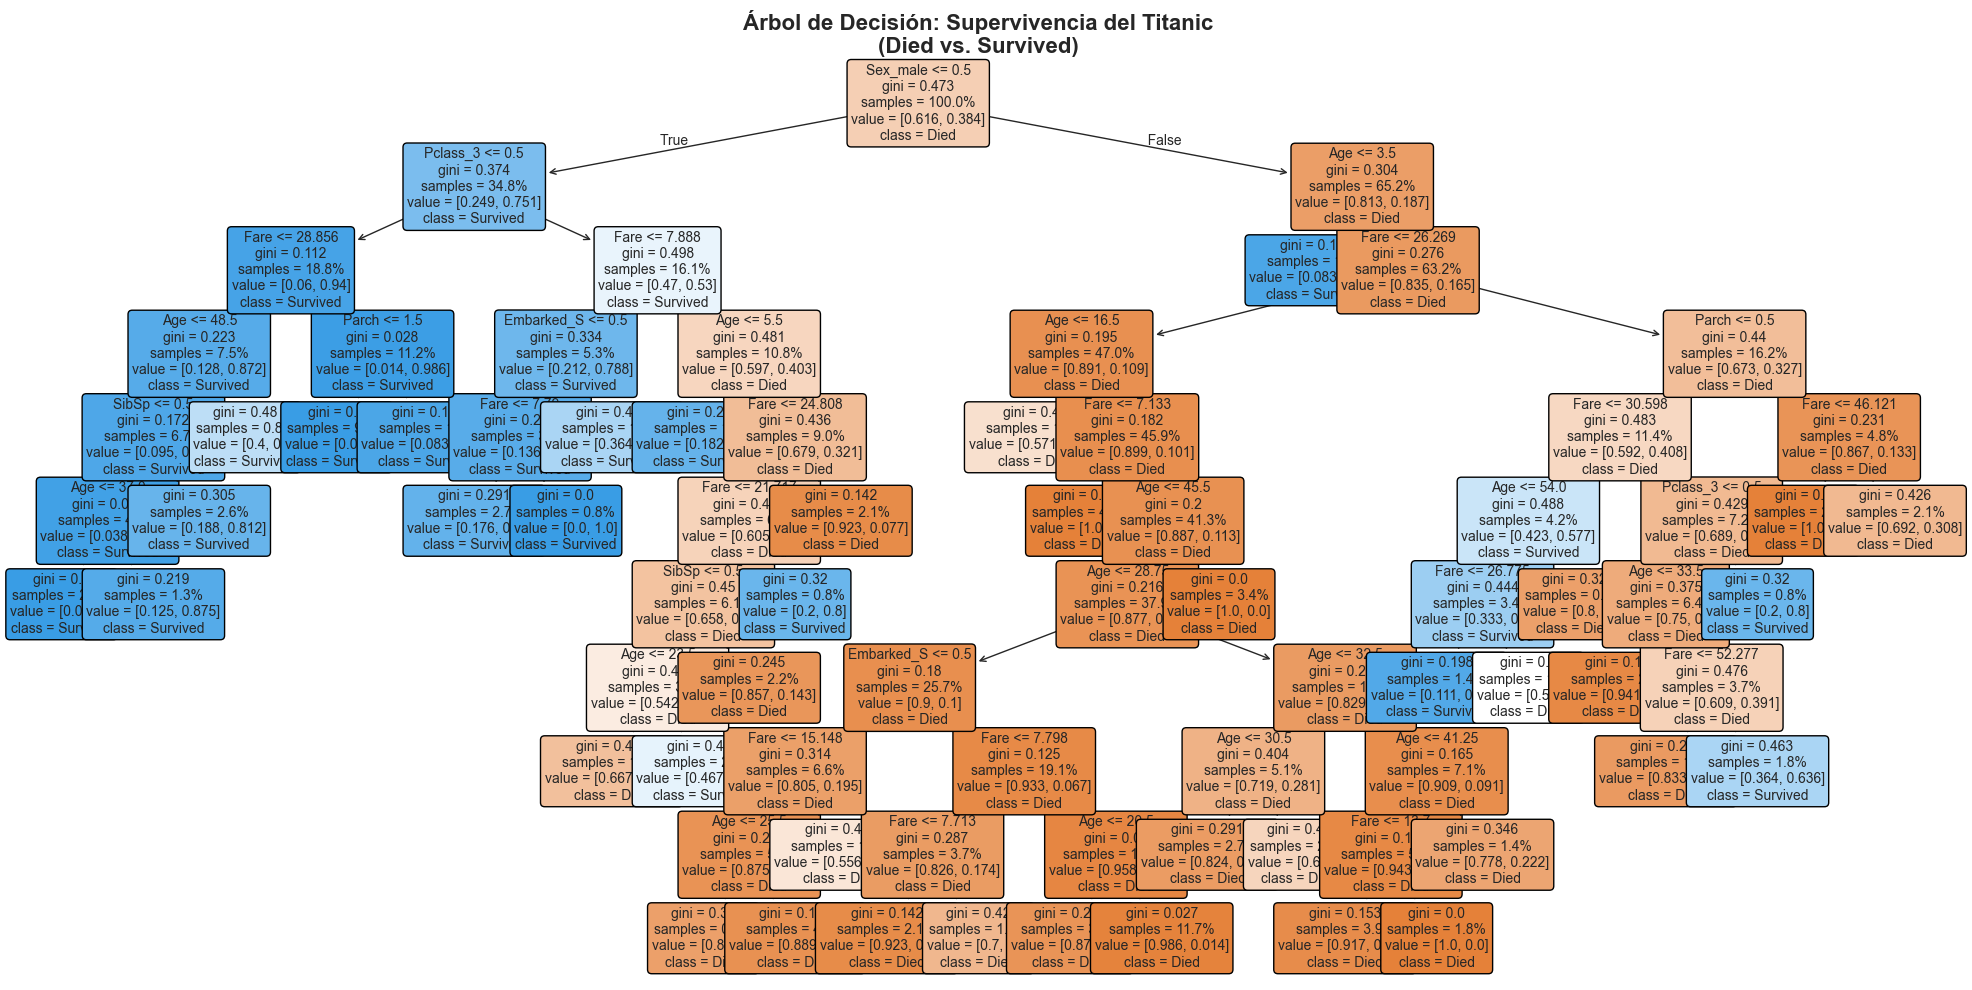


✓ Árbol visualizado

Interpretación del árbol:
  - Nodos NARANJAS: Mayoría de pasajeros MURIERON
  - Nodos AZULES: Mayoría de pasajeros SOBREVIVIERON
  - Cada nodo muestra: condición de split, gini, samples, value
  - Las ramas muestran las reglas de decisión


In [16]:
print("=== VISUALIZANDO EL ÁRBOL DE DECISIÓN ===")

# Crear figura grande para el árbol
plt.figure(figsize=(20, 10))

# Graficar árbol de decisión
plot_tree(
    arbol_titanic,
    feature_names=X.columns,
    class_names=['Died', 'Survived'],
    filled=True,              # Colorear nodos según clase mayoritaria
    rounded=True,             # Nodos redondeados
    fontsize=10,
    proportion=True           # Mostrar proporciones en lugar de conteos
)

plt.title("Árbol de Decisión: Supervivencia del Titanic\n(Died vs. Survived)", 
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Árbol visualizado")
print("\nInterpretación del árbol:")
print("  - Nodos NARANJAS: Mayoría de pasajeros MURIERON")
print("  - Nodos AZULES: Mayoría de pasajeros SOBREVIVIERON")
print("  - Cada nodo muestra: condición de split, gini, samples, value")
print("  - Las ramas muestran las reglas de decisión")

## PASO 9: HACER PREDICCIONES EN EL CONJUNTO TEST

In [ ]:
print("=== PREDICCIONES EN CONJUNTO TEST ===")

# Predecir clases (0 = Died, 1 = Survived)
predicciones_clase = arbol_titanic.predict(X_test)

# Predecir probabilidades (útil para curva ROC)
predicciones_prob = arbol_titanic.predict_proba(X_test)

print("\nPrimeras 10 predicciones:\n")
print(f"{'Real':<12} {'Predicho':<12} {'P(Died)':<12} {'P(Survived)'}")
print("-" * 50)

label_map = {0: 'Died', 1: 'Survived'}

for i in range(10):
    real = label_map[y_test.iloc[i]]
    pred = label_map[predicciones_clase[i]]
    prob_died = predicciones_prob[i, 0]
    prob_survived = predicciones_prob[i, 1]
    
    print(f"{real:<12} {pred:<12} {prob_died:<12.4f} {prob_survived:.4f}")

=== PREDICCIONES EN CONJUNTO TEST ===

Primeras 10 predicciones:

Real         Predicho     P(Died)      P(Survived)
--------------------------------------------------
Died         Died         0.8333       0.1667
Died         Died         0.8696       0.1304
Died         Died         0.8889       0.1111
Survived     Died         1.0000       0.0000
Survived     Died         0.7778       0.2222
Died         Died         0.6923       0.3077
Died         Died         1.0000       0.0000
Survived     Survived     0.0000       1.0000
Died         Died         0.8235       0.1765
Survived     Survived     0.0000       1.0000


## PASO 10: MATRIZ DE CONFUSIÓN

In [ ]:
print("=== MATRIZ DE CONFUSIÓN ===")

# Crear matriz de confusión
cm = confusion_matrix(y_test, predicciones_clase)

# Extraer valores individuales
TN, FP, FN, TP = cm.ravel()

print("\nDESGLOSE DE LA MATRIZ DE CONFUSIÓN:\n")
print("                 Predicho")
print("                 Died      Survived")
print("           -------------------------")
print(f"  Died     |   {TN:4d}   |  {FN:4d}   | (Realmente murieron)")
print(f"  Survived |   {FP:4d}   |  {TP:4d}   | (Realmente sobrevivieron)")
print("           -------------------------\n")

print("Interpretación:")
print(f"  True Negatives (TN):  {TN:4d} - Muertes correctamente predichas")
print(f"  False Positives (FP): {FP:4d} - Predijimos sobrevivencia pero murieron")
print(f"  False Negatives (FN): {FN:4d} - Predijimos muerte pero sobrevivieron")
print(f"  True Positives (TP):  {TP:4d} - Sobrevivencias correctamente predichas")

=== MATRIZ DE CONFUSIÓN ===

DESGLOSE DE LA MATRIZ DE CONFUSIÓN:

                 Predicho
                 Died      Survived
           -------------------------
  Died     |    140   |    38   | (Realmente murieron)
  Survived |     25   |    65   | (Realmente sobrevivieron)
           -------------------------

Interpretación:
  True Negatives (TN):   140 - Muertes correctamente predichas
  False Positives (FP):   25 - Predijimos sobrevivencia pero murieron
  False Negatives (FN):   38 - Predijimos muerte pero sobrevivieron
  True Positives (TP):    65 - Sobrevivencias correctamente predichas


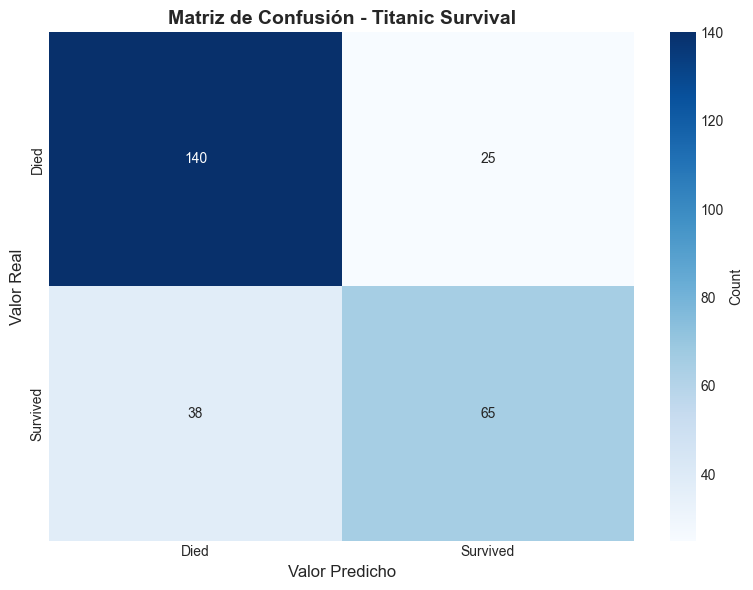

In [ ]:
# Visualizar matriz de confusión con heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['Died', 'Survived'],
    yticklabels=['Died', 'Survived'],
    cbar_kws={'label': 'Count'}
)

plt.title('Matriz de Confusión - Titanic Survival', fontsize=14, fontweight='bold')
plt.ylabel('Valor Real', fontsize=12)
plt.xlabel('Valor Predicho', fontsize=12)
plt.tight_layout()
plt.show()

## PASO 11: MÉTRICAS DE CLASIFICACIÓN DETALLADAS

In [ ]:
print("=== MÉTRICAS DE CLASIFICACIÓN ===")

# Calcular métricas
accuracy = accuracy_score(y_test, predicciones_clase)
precision = precision_score(y_test, predicciones_clase)
recall = recall_score(y_test, predicciones_clase)
f1 = f1_score(y_test, predicciones_clase)
specificity = TN / (TN + FP)
fpr = FP / (FP + TN)

print("\nMÉTRICAS PRINCIPALES:\n")

print(f"1. ACCURACY (Exactitud):           {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("   → Proporción de predicciones correctas\n")

print(f"2. PRECISION (Valor Predictivo +): {precision:.4f} ({precision * 100:.2f}%)")
print("   → De los que predijimos SURVIVED, ¿cuántos realmente sobrevivieron?")
print("   → Fórmula: TP / (TP + FP)\n")

print(f"3. RECALL (Sensibilidad, TPR):     {recall:.4f} ({recall * 100:.2f}%)")
print("   → De los que realmente SURVIVED, ¿cuántos logramos detectar?")
print("   → Fórmula: TP / (TP + FN)\n")

print(f"4. SPECIFICITY (Especificidad):    {specificity:.4f} ({specificity * 100:.2f}%)")
print("   → De los que realmente DIED, ¿cuántos identificamos correctamente?")
print("   → Fórmula: TN / (TN + FP)\n")

print(f"5. F1-SCORE (Media armónica):      {f1:.4f}")
print("   → Balance entre Precision y Recall\n")

print(f"6. FALSE POSITIVE RATE (FPR):      {fpr:.4f} ({fpr * 100:.2f}%)")
print("   → Proporción de muertes mal clasificadas como supervivencias")

=== MÉTRICAS DE CLASIFICACIÓN ===

MÉTRICAS PRINCIPALES:

1. ACCURACY (Exactitud):           0.7649 (76.49%)
   → Proporción de predicciones correctas

2. PRECISION (Valor Predictivo +): 0.7222 (72.22%)
   → De los que predijimos SURVIVED, ¿cuántos realmente sobrevivieron?
   → Fórmula: TP / (TP + FP)

3. RECALL (Sensibilidad, TPR):     0.6311 (63.11%)
   → De los que realmente SURVIVED, ¿cuántos logramos detectar?
   → Fórmula: TP / (TP + FN)

4. SPECIFICITY (Especificidad):    0.8485 (84.85%)
   → De los que realmente DIED, ¿cuántos identificamos correctamente?
   → Fórmula: TN / (TN + FP)

5. F1-SCORE (Media armónica):      0.6736
   → Balance entre Precision y Recall

6. FALSE POSITIVE RATE (FPR):      0.1515 (15.15%)
   → Proporción de muertes mal clasificadas como supervivencias


In [ ]:
# Reporte de clasificación completo
print("\n" + "="*50)
print("REPORTE DE CLASIFICACIÓN COMPLETO (scikit-learn):")
print("="*50 + "\n")

print(classification_report(
    y_test, 
    predicciones_clase,
    target_names=['Died', 'Survived']
))

## PASO 12: INTERPRETACIÓN EN CONTEXTO DEL TITANIC

In [ ]:
print("=== INTERPRETACIÓN EN EL CONTEXTO DEL TITANIC ===")
print("\n¿QUÉ SIGNIFICA CADA MÉTRICA PARA LA TRAGEDIA DEL TITANIC?\n")

print("• RECALL (Sensibilidad):")
print("  → '¿Cuántos SUPERVIVIENTES logramos identificar correctamente?'")
print(f"  → Con recall = {recall * 100:.2f}%, estamos identificando {recall * 100:.0f} de cada 100 supervivientes")
print("  → Recall BAJO significa que estamos clasificando supervivientes como muertos\n")

print("• PRECISION:")
print("  → 'Cuando predecimos que alguien sobrevivió, ¿qué tan seguros estamos?'")
print(f"  → Con precision = {precision * 100:.2f}%, de cada 100 predicciones de 'sobrevivió',")
print(f"     {precision * 100:.0f} realmente sobrevivieron y {(1 - precision) * 100:.0f} murieron")
print("  → Precision BAJA significa predicciones optimistas pero incorrectas\n")

print("• F1-SCORE:")
print("  → Balance entre ambos objetivos")

if f1 > 0.8:
    evaluacion = "muy buen"
elif f1 > 0.7:
    evaluacion = "buen"
else:
    evaluacion = "aceptable"

print(f"  → F1 = {f1:.4f} indica un {evaluacion} balance")

=== INTERPRETACIÓN EN EL CONTEXTO DEL TITANIC ===

¿QUÉ SIGNIFICA CADA MÉTRICA PARA LA TRAGEDIA DEL TITANIC?

• RECALL (Sensibilidad):
  → '¿Cuántos SUPERVIVIENTES logramos identificar correctamente?'
  → Con recall = 63.11%, estamos identificando 63 de cada 100 supervivientes
  → Recall BAJO significa que estamos clasificando supervivientes como muertos

• PRECISION:
  → 'Cuando predecimos que alguien sobrevivió, ¿qué tan seguros estamos?'
  → Con precision = 72.22%, de cada 100 predicciones de 'sobrevivió',
     72 realmente sobrevivieron y 28 murieron
  → Precision BAJA significa predicciones optimistas pero incorrectas

• F1-SCORE:
  → Balance entre ambos objetivos
  → F1 = 0.6736 indica un aceptable balance


## PASO 13: CURVA ROC Y AUC

In [ ]:
print("=== CURVA ROC Y ÁREA BAJO LA CURVA (AUC) ===")

# Extraer probabilidad de "Survived" (clase positiva = 1)
prob_survived = predicciones_prob[:, 1]

# Calcular curva ROC
fpr_roc, tpr_roc, thresholds = roc_curve(y_test, prob_survived)

# Calcular AUC
auc_value = roc_auc_score(y_test, prob_survived)

print("\nINFORMACIÓN DE LA CURVA ROC:\n")
print(f"AUC (Área bajo la curva): {auc_value:.4f}\n")

print("INTERPRETACIÓN DEL AUC:")
print("  • AUC = 1.0   → Clasificador perfecto")
print("  • AUC = 0.9   → Excelente")
print("  • AUC = 0.8   → Muy bueno")
print("  • AUC = 0.7   → Bueno")
print("  • AUC = 0.5   → Aleatorio (línea diagonal)\n")

if auc_value > 0.85:
    evaluacion_auc = "MUY BUENO"
elif auc_value > 0.75:
    evaluacion_auc = "BUENO"
elif auc_value > 0.65:
    evaluacion_auc = "ACEPTABLE"
else:
    evaluacion_auc = "MEJORABLE"

print(f"Con AUC = {auc_value:.4f}, nuestro modelo es {evaluacion_auc}")

=== CURVA ROC Y ÁREA BAJO LA CURVA (AUC) ===

INFORMACIÓN DE LA CURVA ROC:

AUC (Área bajo la curva): 0.8022

INTERPRETACIÓN DEL AUC:
  • AUC = 1.0   → Clasificador perfecto
  • AUC = 0.9   → Excelente
  • AUC = 0.8   → Muy bueno
  • AUC = 0.7   → Bueno
  • AUC = 0.5   → Aleatorio (línea diagonal)

Con AUC = 0.8022, nuestro modelo es BUENO


## PASO 14: GRAFICAR CURVA ROC


=== GRAFICANDO CURVA ROC ===


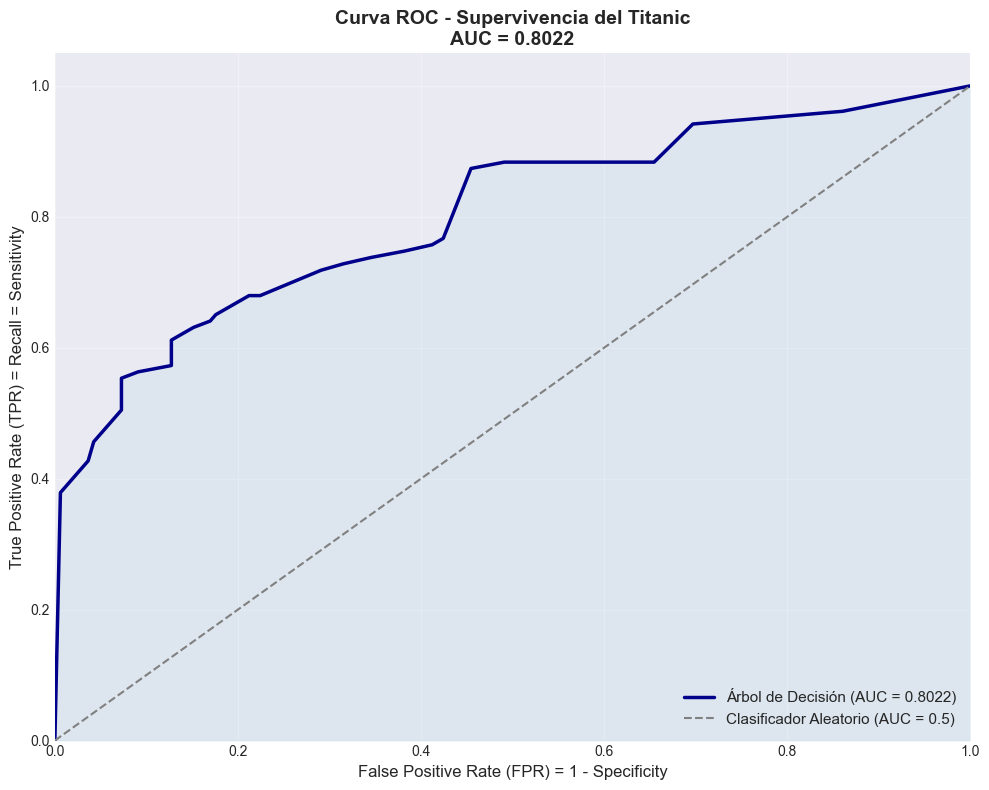


✓ Curva ROC graficada

COMPONENTES DE LA CURVA ROC:

• EJE X: False Positive Rate (FPR) = 1 - Specificity
  → Proporción de MUERTES clasificadas erróneamente como SUPERVIVENCIAS

• EJE Y: True Positive Rate (TPR) = Recall = Sensitivity
  → Proporción de SUPERVIVENCIAS detectadas correctamente

• LÍNEA DIAGONAL: Clasificador aleatorio
• LÍNEA AZUL: Nuestro árbol de decisión
• ÁREA SOMBREADA: Representa el AUC


In [ ]:
print("\n=== GRAFICANDO CURVA ROC ===")

# Crear figura
plt.figure(figsize=(10, 8))

# Graficar curva ROC
plt.plot(
    fpr_roc, tpr_roc,
    color='darkblue',
    lw=2.5,
    label=f'Árbol de Decisión (AUC = {auc_value:.4f})'
)

# Línea diagonal de referencia (clasificador aleatorio)
plt.plot(
    [0, 1], [0, 1],
    color='gray',
    lw=1.5,
    linestyle='--',
    label='Clasificador Aleatorio (AUC = 0.5)'
)

# Sombrear área bajo la curva
plt.fill_between(fpr_roc, tpr_roc, alpha=0.2, color='lightblue')

# Configuración del gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR) = 1 - Specificity', fontsize=12)
plt.ylabel('True Positive Rate (TPR) = Recall = Sensitivity', fontsize=12)
plt.title(f'Curva ROC - Supervivencia del Titanic\nAUC = {auc_value:.4f}', 
          fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n✓ Curva ROC graficada")
print("\nCOMPONENTES DE LA CURVA ROC:\n")
print("• EJE X: False Positive Rate (FPR) = 1 - Specificity")
print("  → Proporción de MUERTES clasificadas erróneamente como SUPERVIVENCIAS\n")
print("• EJE Y: True Positive Rate (TPR) = Recall = Sensitivity")
print("  → Proporción de SUPERVIVENCIAS detectadas correctamente\n")
print("• LÍNEA DIAGONAL: Clasificador aleatorio")
print("• LÍNEA AZUL: Nuestro árbol de decisión")
print("• ÁREA SOMBREADA: Representa el AUC")

## PASO 15: ENCONTRAR EL MEJOR THRESHOLD (YOUDEN)

In [ ]:
print("=== SELECCIÓN DEL MEJOR THRESHOLD ===")

# Calcular índice de Youden para cada threshold
# J = Sensitivity + Specificity - 1
youden_index = tpr_roc - fpr_roc

# Encontrar threshold óptimo
idx_best = np.argmax(youden_index)
best_threshold = thresholds[idx_best]
best_tpr = tpr_roc[idx_best]
best_fpr = fpr_roc[idx_best]
best_specificity = 1 - best_fpr
best_youden = youden_index[idx_best]

print("\nÍndice de Youden (J = Sensitivity + Specificity - 1)")
print("  → Maximiza la distancia de la curva ROC a la diagonal\n")

print(f"Threshold óptimo: {best_threshold:.4f}")
print(f"  Sensitivity (TPR): {best_tpr:.4f}")
print(f"  Specificity:       {best_specificity:.4f}")
print(f"  Índice J:          {best_youden:.4f}")

print("\nInterpretación:")
print(f"  → Si usamos threshold = {best_threshold:.4f} en lugar de 0.5 (default),")
print(f"     maximizamos el balance entre detectar supervivientes y evitar falsos positivos")

=== SELECCIÓN DEL MEJOR THRESHOLD ===

Índice de Youden (J = Sensitivity + Specificity - 1)
  → Maximiza la distancia de la curva ROC a la diagonal

Threshold óptimo: 0.6000
  Sensitivity (TPR): 0.6117
  Specificity:       0.8727
  Índice J:          0.4844

Interpretación:
  → Si usamos threshold = 0.6000 en lugar de 0.5 (default),
     maximizamos el balance entre detectar supervivientes y evitar falsos positivos


## PASO 16: DISCUSIÓN SOBRE SESGOS Y EQUIDAD

In [ ]:
print("=" * 70)
print("DISCUSIÓN: SESGOS Y EQUIDAD EN MODELOS PREDICTIVOS")
print("=" * 70)

print("\nREFLEXIÓN CRÍTICA SOBRE EL MODELO:\n")

print("1. SESGOS HISTÓRICOS CAPTURADOS:")
print("   • El modelo aprende de datos históricos del desastre del Titanic")
print("   • Estos datos reflejan sesgos sociales de 1912:")
print("     - Género: 'Mujeres y niños primero' → Sesgo favorable a mujeres")
print("     - Clase social: Pasajeros de 1ra clase tuvieron acceso preferencial")
print("     - Ubicación: Cabinas cercanas a cubiertas superiores → mayor supervivencia\n")

print("2. IMPLICACIONES ÉTICAS:")
print("   • ¿Es 'justo' un modelo que predice mejor para ciertos grupos?")
print("   • Si usáramos este modelo para decisiones reales:")
print("     - ¿Estaríamos perpetuando inequidades históricas?")
print("     - ¿Deberíamos penalizar o rebalancear según género/clase?\n")

print("3. PRECISIÓN vs. EQUIDAD:")
print("   • Modelo preciso ≠ Modelo justo")
print("   • Alta accuracy puede esconder disparidades entre grupos")
print("   • Importante analizar métricas SEPARADAS por grupo:")
print("     - Recall para hombres vs. mujeres")
print("     - Precision para 1ra clase vs. 3ra clase\n")

print("4. LECCIONES PARA ML EN LA PRÁCTICA:")
print("   ✓ Siempre explorar sesgos en los datos históricos")
print("   ✓ Evaluar fairness además de accuracy")
print("   ✓ Considerar el impacto social de las predicciones")
print("   ✓ Documentar limitaciones y sesgos del modelo")

DISCUSIÓN: SESGOS Y EQUIDAD EN MODELOS PREDICTIVOS

REFLEXIÓN CRÍTICA SOBRE EL MODELO:

1. SESGOS HISTÓRICOS CAPTURADOS:
   • El modelo aprende de datos históricos del desastre del Titanic
   • Estos datos reflejan sesgos sociales de 1912:
     - Género: 'Mujeres y niños primero' → Sesgo favorable a mujeres
     - Clase social: Pasajeros de 1ra clase tuvieron acceso preferencial
     - Ubicación: Cabinas cercanas a cubiertas superiores → mayor supervivencia

2. IMPLICACIONES ÉTICAS:
   • ¿Es 'justo' un modelo que predice mejor para ciertos grupos?
   • Si usáramos este modelo para decisiones reales:
     - ¿Estaríamos perpetuando inequidades históricas?
     - ¿Deberíamos penalizar o rebalancear según género/clase?

3. PRECISIÓN vs. EQUIDAD:
   • Modelo preciso ≠ Modelo justo
   • Alta accuracy puede esconder disparidades entre grupos
   • Importante analizar métricas SEPARADAS por grupo:
     - Recall para hombres vs. mujeres
     - Precision para 1ra clase vs. 3ra clase

4. LECCIONES

## PASO 17: ANÁLISIS DE EQUIDAD POR GRUPO

In [ ]:
print("\n=== ANÁLISIS DE EQUIDAD: MÉTRICAS POR SEXO ===")

# Crear DataFrame con predicciones
# Necesitamos recuperar las variables originales antes del encoding
# Usamos los índices de X_test para recuperar del dataset original
test_indices = X_test.index
titanic_test_original = titanic.loc[test_indices].copy()
titanic_test_original['Predicted'] = predicciones_clase
titanic_test_original['Actual'] = y_test.values

def calcular_metricas_grupo(df_grupo, nombre_grupo):
    """Calcula métricas de clasificación para un subgrupo específico"""
    
    if len(df_grupo) == 0:
        return None
    
    y_true = df_grupo['Actual']
    y_pred = df_grupo['Predicted']
    
    # Si hay muy pocas observaciones, puede no haber ambas clases
    if len(y_true.unique()) < 2 or len(y_pred.unique()) < 2:
        acc = accuracy_score(y_true, y_pred)
        return {
            'Grupo': nombre_grupo,
            'N': len(df_grupo),
            'Accuracy': round(acc, 4),
            'Recall': None,
            'Precision': None
        }
    
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    
    return {
        'Grupo': nombre_grupo,
        'N': len(df_grupo),
        'Accuracy': round(acc, 4),
        'Recall': round(rec, 4) if rec > 0 else None,
        'Precision': round(prec, 4) if prec > 0 else None
    }

# Calcular métricas por sexo
metricas_hombres = calcular_metricas_grupo(
    titanic_test_original[titanic_test_original['Sex'] == 'male'],
    'Hombres'
)

metricas_mujeres = calcular_metricas_grupo(
    titanic_test_original[titanic_test_original['Sex'] == 'female'],
    'Mujeres'
)

# Calcular métricas por clase
metricas_1st = calcular_metricas_grupo(
    titanic_test_original[titanic_test_original['Pclass'] == 1],
    '1ra Clase'
)

metricas_2nd = calcular_metricas_grupo(
    titanic_test_original[titanic_test_original['Pclass'] == 2],
    '2da Clase'
)

metricas_3rd = calcular_metricas_grupo(
    titanic_test_original[titanic_test_original['Pclass'] == 3],
    '3ra Clase'
)

# Crear DataFrames de resultados
metricas_sexo = pd.DataFrame([metricas_hombres, metricas_mujeres])
metricas_clase = pd.DataFrame([metricas_1st, metricas_2nd, metricas_3rd])

print("\nMÉTRICAS POR SEXO:")
print(metricas_sexo.to_string(index=False))

print("\n\nMÉTRICAS POR CLASE SOCIOECONÓMICA:")
print(metricas_clase.to_string(index=False))

print("\n\nINTERPRETACIÓN:")
print("• Diferencias en Recall entre grupos indican sesgo en la capacidad de detectar supervivientes")
print("• Diferencias en Precision indican sesgo en la confiabilidad de predicciones positivas")
print("• Estas disparidades reflejan tanto los sesgos históricos como las limitaciones del modelo")


=== ANÁLISIS DE EQUIDAD: MÉTRICAS POR SEXO ===

MÉTRICAS POR SEXO:
  Grupo   N  Accuracy  Recall  Precision
Hombres 171    0.7836  0.1818     0.3750
Mujeres  97    0.7320  0.8429     0.7973


MÉTRICAS POR CLASE SOCIOECONÓMICA:
    Grupo   N  Accuracy  Recall  Precision
1ra Clase  69    0.7391  0.7143     0.8333
2da Clase  54    0.9259  0.8929     0.9615
3ra Clase 145    0.7172  0.3030     0.3571


INTERPRETACIÓN:
• Diferencias en Recall entre grupos indican sesgo en la capacidad de detectar supervivientes
• Diferencias en Precision indican sesgo en la confiabilidad de predicciones positivas
• Estas disparidades reflejan tanto los sesgos históricos como las limitaciones del modelo


## PASO 18: RESUMEN FINAL Y CONCLUSIONES

In [ ]:
print("\n" + "=" * 70)
print("RESUMEN FINAL")
print("=" * 70)

print("\nDATASET TITANIC SURVIVAL:")
print(f"  • Total pasajeros: {n_total}")
print(f"  • Train: {n_train} | Test: {n_test}")
print(f"  • Tasa supervivencia real: {prop_clases['Survived']:.1f}%\n")

print("ÁRBOL DE DECISIÓN (DecisionTreeClassifier):")
print(f"  • Variable más importante: {importancia.iloc[0]['Variable']}")
print(f"  • Profundidad del árbol: {arbol_titanic.get_depth()}")
print(f"  • Número de hojas: {arbol_titanic.get_n_leaves()}\n")

print("PERFORMANCE EN TEST SET:")
print(f"  • Accuracy:    {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"  • Precision:   {precision:.4f} ({precision * 100:.2f}%)")
print(f"  • Recall:      {recall:.4f} ({recall * 100:.2f}%)")
print(f"  • F1-Score:    {f1:.4f}")
print(f"  • AUC:         {auc_value:.4f}\n")

print("INTERPRETACIÓN:")
if auc_value > 0.85:
    print("  ✓ El modelo tiene un performance MUY BUENO")
    print("  ✓ Las variables sociodemográficas son muy predictivas")
elif auc_value > 0.75:
    print("  ✓ El modelo tiene un performance BUENO")
    print("  ✓ Hay patrones claros en los datos históricos")
else:
    print("  ⚠ El modelo tiene un performance ACEPTABLE")
    print("  ⚠ Podría mejorarse con feature engineering o modelos más complejos")

print("\n" + "=" * 70)
print("FIN DEL ANÁLISIS")
print("=" * 70)


RESUMEN FINAL

DATASET TITANIC SURVIVAL:
  • Total pasajeros: 891
  • Train: 623 | Test: 268
  • Tasa supervivencia real: 38.4%

ÁRBOL DE DECISIÓN (DecisionTreeClassifier):
  • Variable más importante: Sex_male
  • Profundidad del árbol: 10
  • Número de hojas: 40

PERFORMANCE EN TEST SET:
  • Accuracy:    0.7649 (76.49%)
  • Precision:   0.7222 (72.22%)
  • Recall:      0.6311 (63.11%)
  • F1-Score:    0.6736
  • AUC:         0.8022

INTERPRETACIÓN:
  ✓ El modelo tiene un performance BUENO
  ✓ Hay patrones claros en los datos históricos

FIN DEL ANÁLISIS


## PRÓXIMOS PASOS SUGERIDOS

### 1. Feature Engineering:
- Extraer 'Title' del nombre (Mr., Mrs., Miss., Master.)
- Crear variable 'FamilySize' = SibSp + Parch + 1
- Crear variable 'IsAlone' (FamilySize == 1)
- Agrupar tarifas en rangos (low/medium/high fare)

### 2. Comparar con otros algoritmos:
- Logistic Regression (baseline interpretable)
- Random Forest (ensemble de árboles)
- XGBoost (gradient boosting)
- SVM (Support Vector Machine)

### 3. Análisis de Fairness:
- Calcular Disparate Impact Ratio entre grupos
- Evaluar Equal Opportunity (igual TPR para ambos sexos)
- Considerar técnicas de debiasing (reweighting, resampling)

### 4. Validación más robusta:
- K-Fold Cross-Validation (en lugar de single split)
- Stratified CV para mantener balance de clases

### 5. Interpretabilidad:
- Analizar reglas de decisión del árbol
- Identificar casos mal clasificados
- SHAP values para explicar predicciones individuales

---

## REFLEXIÓN FINAL

El modelo del Titanic es un recordatorio de que los datos históricos contienen sesgos de su época. Como científicos de datos, debemos:

1. **Reconocer estos sesgos explícitamente**
2. **Evaluar el impacto en diferentes grupos**
3. **Considerar las implicaciones éticas de nuestros modelos**
4. **Buscar equidad además de exactitud**

---

**✓ Notebook ejecutado exitosamente**